In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
odisha = pd.read_csv(r"C:\Users\LOQ\OneDrive\Desktop\INT 234 PREDICTIVE ANALYSIS\dataset\river_discharge_tele_hr_cwc_od_1970_2025.csv")
sikkim = pd.read_csv(r"C:\Users\LOQ\OneDrive\Desktop\INT 234 PREDICTIVE ANALYSIS\dataset\river_discharge_tele_hr_cwc_sk_1970_2025.csv")
uttarakhand = pd.read_csv(r"C:\Users\LOQ\OneDrive\Desktop\INT 234 PREDICTIVE ANALYSIS\dataset\river_discharge_tele_hr_cwc_uk_1970_2025.csv")
west_bengal = pd.read_csv(r"C:\Users\LOQ\OneDrive\Desktop\INT 234 PREDICTIVE ANALYSIS\dataset\river_discharge_tele_hr_cwc_wb_1970_2025.csv")
print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
df = pd.concat([odisha, sikkim, uttarakhand, west_bengal], ignore_index=True)
print("Combined Dataset Shape:", df.shape)
display(df.head())

Combined Dataset Shape: (549369, 20)


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Telemetry Hourly River Water Discharge (m3/sec)
0,1,Champua_1,CWC,21,Odisha,361,KENDUJHAR,-,-,-,-,-,-,-,-,-,22.065833,85.682222,01-09-2022 00:45,56.0
1,2,Champua_1,CWC,21,Odisha,361,KENDUJHAR,-,-,-,-,-,-,-,-,-,22.065833,85.682222,01-09-2022 01:00,51.0
2,3,Champua_1,CWC,21,Odisha,361,KENDUJHAR,-,-,-,-,-,-,-,-,-,22.065833,85.682222,01-09-2022 01:15,52.0
3,4,Champua_1,CWC,21,Odisha,361,KENDUJHAR,-,-,-,-,-,-,-,-,-,22.065833,85.682222,01-09-2022 01:30,57.0
4,5,Champua_1,CWC,21,Odisha,361,KENDUJHAR,-,-,-,-,-,-,-,-,-,22.065833,85.682222,01-09-2022 08:45,-8909.0


In [4]:
print("Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:")
print(df.duplicated().sum())
print("\nStatistical Summary:")
print(df.describe())

Shape: (549369, 20)

Column Names:
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Telemetry Hourly River Water Discharge (m3/sec)']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 549369 entries, 0 to 549368
Data columns (total 20 columns):
 #   Column                                           Non-Null Count   Dtype  
---  ------                                           --------------   -----  
 0   SlNo                                             549369 non-null  int64  
 1   Station                                          549369 non-null  str    
 2   Agency                                           549369 non-null  str    
 3   State LGD Code                                   549369 non-null  int64  
 4   State                                            549369 non-nu

In [5]:
q_col = "Telemetry Hourly River Water Discharge (m3/sec)"
df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    errors="coerce",
    dayfirst=True
)
df[q_col] = pd.to_numeric(
    df[q_col],
    errors="coerce"
)
df = df.dropna(
    subset=["Data Acquisition Time", "State", "Station", q_col]
)
df = df.drop_duplicates()
df = df[df[q_col] >= 0]
df["State_Station"] = (
    df["State"].astype(str) + "_" +
    df["Station"].astype(str)
)
df = df.sort_values(
    ["State_Station", "Data Acquisition Time"]
)
df = df.reset_index(drop=True)
print("Cleaned Dataset Shape:", df.shape)
print(df.head())
print(df.isnull().sum())

Cleaned Dataset Shape: (487730, 21)
   SlNo    Station Agency  ...  Data Acquisition Time Telemetry Hourly River Water Discharge (m3/sec)     State_Station
0     1  Champua_1    CWC  ...    2022-09-01 00:45:00                                            56.0  Odisha_Champua_1
1     2  Champua_1    CWC  ...    2022-09-01 01:00:00                                            51.0  Odisha_Champua_1
2     3  Champua_1    CWC  ...    2022-09-01 01:15:00                                            52.0  Odisha_Champua_1
3     4  Champua_1    CWC  ...    2022-09-01 01:30:00                                            57.0  Odisha_Champua_1
4     6  Champua_1    CWC  ...    2022-09-01 09:00:00                                            59.0  Odisha_Champua_1

[5 rows x 21 columns]
SlNo                                               0
Station                                            0
Agency                                             0
State LGD Code                                     0
State    

In [6]:
print(df["State"].value_counts())
print("\nNumber of Stations:")
print(df.groupby("State")["Station"].nunique())
print("\nDischarge Statistics:")
print(df.groupby("State")[q_col].describe())

State
Uttarakhand    349005
Sikkim          88386
West Bengal     34605
Odisha          15734
Name: count, dtype: int64

Number of Stations:
State
Odisha         1
Sikkim         4
Uttarakhand    7
West Bengal    2
Name: Station, dtype: int64

Discharge Statistics:
                count        mean          std  min    25%     50%      75%         max
State                                                                                  
Odisha        15734.0   15.285306    27.176149  0.0   1.00   4.000   14.000     180.000
Sikkim        88386.0  338.950421  3743.061601  0.0   4.28  34.955  222.815   99999.990
Uttarakhand  349005.0  147.785184   891.289043  0.0  11.00  42.000  164.000  100000.000
West Bengal   34605.0   60.709334    55.154947  0.0  24.60  38.720   72.560     401.481


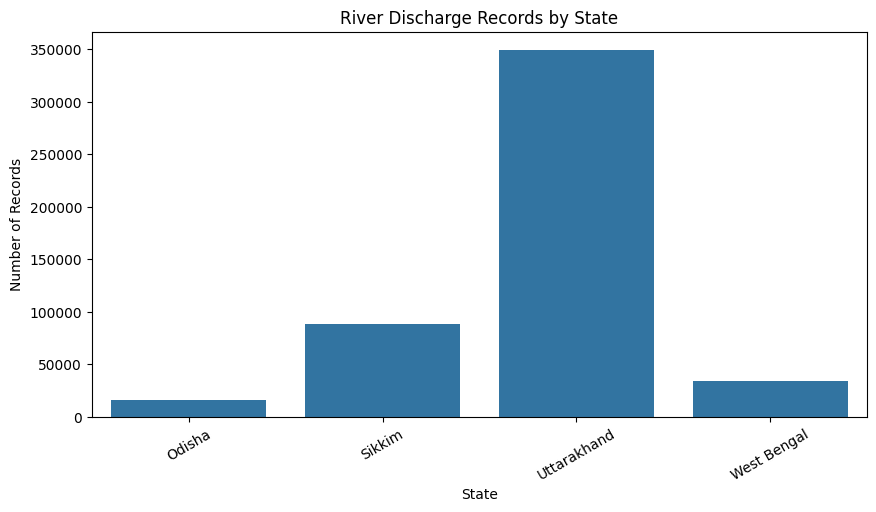

In [7]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="State")
plt.title("River Discharge Records by State")
plt.xlabel("State")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()

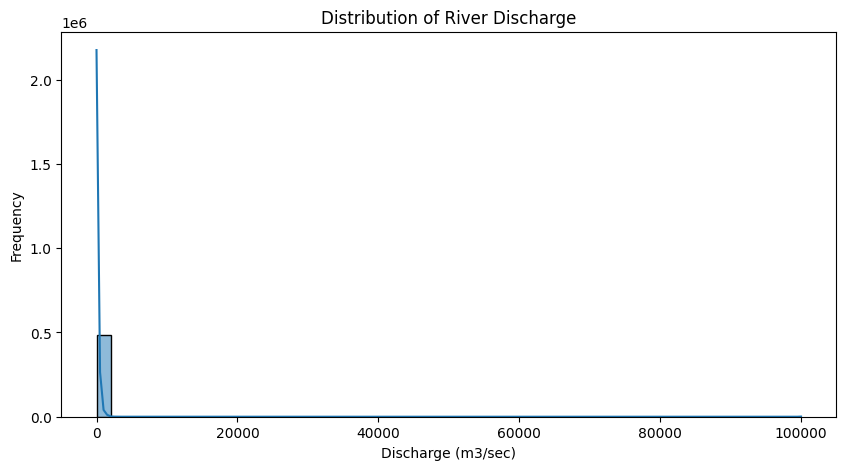

In [8]:
plt.figure(figsize=(10,5))

sns.histplot(df[q_col], bins=50, kde=True)

plt.title("Distribution of River Discharge")
plt.xlabel("Discharge (m3/sec)")
plt.ylabel("Frequency")

plt.show()

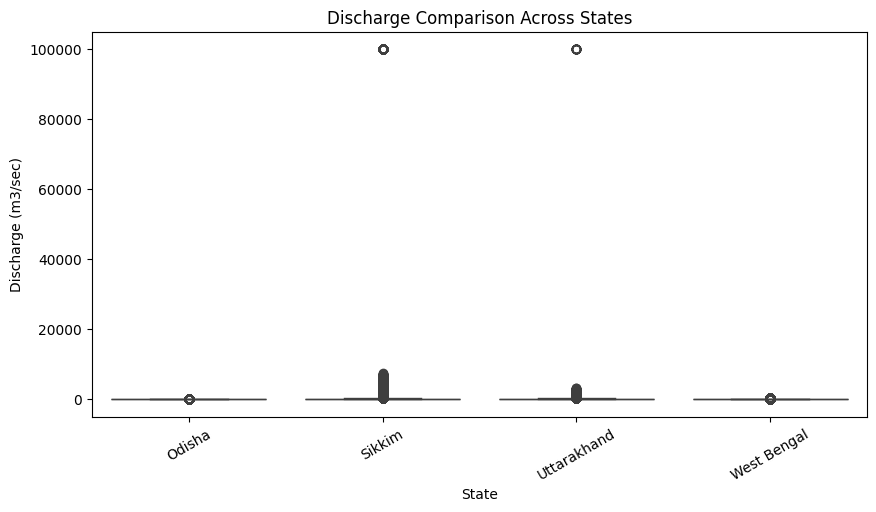

In [9]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x="State", y=q_col)
plt.title("Discharge Comparison Across States")
plt.xlabel("State")
plt.ylabel("Discharge (m3/sec)")
plt.xticks(rotation=30)
plt.show()

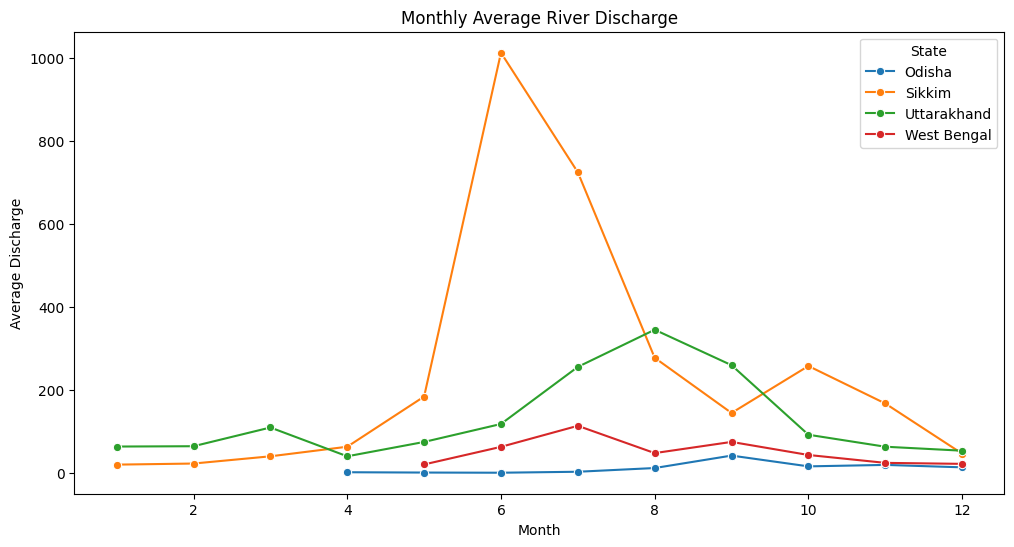

In [10]:
df["Month"] = df["Data Acquisition Time"].dt.month
monthly = df.groupby(["State", "Month"])[q_col].mean().reset_index()
plt.figure(figsize=(12,6))
sns.lineplot(
    data=monthly,
    x="Month",
    y=q_col,
    hue="State",
    marker="o"
)
plt.title("Monthly Average River Discharge")
plt.xlabel("Month")
plt.ylabel("Average Discharge")
plt.show()

In [11]:
df["Lag_1"] = df.groupby("State_Station")[q_col].shift(1)
df["Lag_2"] = df.groupby("State_Station")[q_col].shift(2)
df["Lag_3"] = df.groupby("State_Station")[q_col].shift(3)
df["Rolling_Mean"] = (
    df.groupby("State_Station")[q_col]
    .transform(lambda x: x.shift(1).rolling(4).mean())
)
df["Hour"] = df["Data Acquisition Time"].dt.hour
df["Day"] = df["Data Acquisition Time"].dt.day

df["Month"] = df["Data Acquisition Time"].dt.month

df["Target_Discharge"] = (
    df.groupby("State_Station")[q_col].shift(-1)
)
model_df = df.dropna(
    subset=[
        "Lag_1", "Lag_2", "Lag_3",
        "Rolling_Mean", "Target_Discharge"
    ]
).copy()
print(model_df.shape)
print(model_df.head())

(487660, 29)
   SlNo    Station Agency  State LGD Code   State  ...  Lag_3 Rolling_Mean Hour Day Target_Discharge
4     6  Champua_1    CWC              21  Odisha  ...   51.0        54.00    9   1             40.0
5    10  Champua_1    CWC              21  Odisha  ...   52.0        54.75   10   1             44.0
6    11  Champua_1    CWC              21  Odisha  ...   57.0        52.00   10   1             36.0
7    13  Champua_1    CWC              21  Odisha  ...   59.0        50.00   10   1             42.0
8    17  Champua_1    CWC              21  Odisha  ...   40.0        44.75   11   1             41.0

[5 rows x 29 columns]


In [12]:
split_date = model_df["Data Acquisition Time"].quantile(0.80)

train_df = model_df[
    model_df["Data Acquisition Time"] < split_date
].copy()

test_df = model_df[
    model_df["Data Acquisition Time"] >= split_date
].copy()

thresholds = train_df.groupby("State_Station")[
    "Target_Discharge"
].quantile([0.33, 0.66]).unstack()
thresholds.columns = ["Q33", "Q66"]

global_q33 = train_df["Target_Discharge"].quantile(0.33)

global_q66 = train_df["Target_Discharge"].quantile(0.66)

def assign_risk(data):
    q33 = data["State_Station"].map(
        thresholds["Q33"]
    ).fillna(global_q33)

    q66 = data["State_Station"].map(
        thresholds["Q66"]
    ).fillna(global_q66)

    risk = np.where(
        data["Target_Discharge"] <= q33,
        "Low Risk",
        np.where(
            data["Target_Discharge"] <= q66,
            "Moderate Risk",
            "High Risk"
        )
    )

    return risk

train_df["Risk_Level"] = assign_risk(train_df)

test_df["Risk_Level"] = assign_risk(test_df)

print("Training Risk Distribution:")
print(train_df["Risk_Level"].value_counts())

print("\nTesting Risk Distribution:")
print(test_df["Risk_Level"].value_counts())

Training Risk Distribution:
Risk_Level
Low Risk         132759
High Risk        132005
Moderate Risk    125363
Name: count, dtype: int64

Testing Risk Distribution:
Risk_Level
High Risk        69453
Moderate Risk    18689
Low Risk          9391
Name: count, dtype: int64


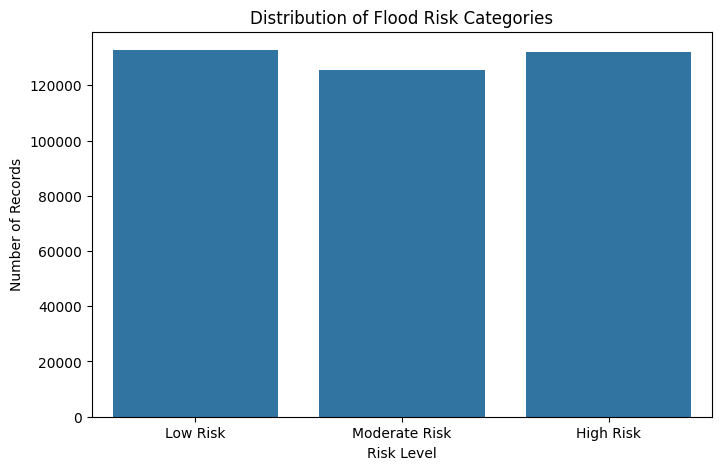

In [13]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=train_df,
    x="Risk_Level",
    order=["Low Risk", "Moderate Risk", "High Risk"]
)

plt.title("Distribution of Flood Risk Categories")
plt.xlabel("Risk Level")
plt.ylabel("Number of Records")

plt.show()

In [14]:
features = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Rolling_Mean",
    "Hour",
    "Day",
    "Month"
]

X_train = train_df[features].copy()

X_test = test_df[features].copy()

station_train = pd.get_dummies(
    train_df["State_Station"],
    dtype=int
)

station_test = pd.get_dummies(
    test_df["State_Station"],
    dtype=int
)

station_test = station_test.reindex(
    columns=station_train.columns,
    fill_value=0
)

X_train = pd.concat(
    [X_train.reset_index(drop=True),
     station_train.reset_index(drop=True)],
    axis=1
)

X_test = pd.concat(
    [X_test.reset_index(drop=True),
     station_test.reset_index(drop=True)],
    axis=1
)

y_train = train_df["Risk_Level"].reset_index(drop=True)

y_test = test_df["Risk_Level"].reset_index(drop=True)

print("X Train:", X_train.shape)
print("X Test:", X_test.shape)
print("Y Train:", y_train.shape)
print("Y Test:", y_test.shape)

X Train: (390127, 21)
X Test: (97533, 21)
Y Train: (390127,)
Y Test: (97533,)


In [15]:
X_train_sample = X_train.sample(
    n=min(30000, len(X_train)),
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

X_test_sample = X_test.sample(
    n=min(10000, len(X_test)),
    random_state=42
)

y_test_sample = y_test.loc[X_test_sample.index]

print("Training Records:", len(X_train_sample))
print("Testing Records:", len(X_test_sample))

Training Records: 30000
Testing Records: 10000


In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_sample)

X_test_scaled = scaler.transform(X_test_sample)

In [17]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_scaled, y_train_sample)

lr_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test_sample, lr_pred))

print(classification_report(
    y_test_sample,
    lr_pred,
    zero_division=0
))

Logistic Regression Accuracy: 0.7758
               precision    recall  f1-score   support

    High Risk       1.00      0.83      0.91      7145
     Low Risk       0.40      0.58      0.47       913
Moderate Risk       0.48      0.67      0.55      1942

     accuracy                           0.78     10000
    macro avg       0.62      0.69      0.65     10000
 weighted avg       0.84      0.78      0.80     10000



In [18]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train_sample)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN Accuracy:",
      accuracy_score(y_test_sample, knn_pred))

print(classification_report(
    y_test_sample,
    knn_pred,
    zero_division=0
))

KNN Accuracy: 0.6807
               precision    recall  f1-score   support

    High Risk       0.91      0.76      0.83      7145
     Low Risk       0.31      0.58      0.40       913
Moderate Risk       0.37      0.45      0.40      1942

     accuracy                           0.68     10000
    macro avg       0.53      0.59      0.54     10000
 weighted avg       0.75      0.68      0.71     10000



In [19]:
dt_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train_sample, y_train_sample)

dt_pred = dt_model.predict(X_test_sample)

print("Decision Tree Accuracy:",
      accuracy_score(y_test_sample, dt_pred))

print(classification_report(
    y_test_sample,
    dt_pred,
    zero_division=0
))

Decision Tree Accuracy: 0.8914
               precision    recall  f1-score   support

    High Risk       0.97      0.91      0.94      7145
     Low Risk       0.87      0.82      0.84       913
Moderate Risk       0.68      0.87      0.76      1942

     accuracy                           0.89     10000
    macro avg       0.84      0.87      0.85     10000
 weighted avg       0.91      0.89      0.90     10000



In [20]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_sample, y_train_sample)

rf_pred = rf_model.predict(X_test_sample)

print("Random Forest Accuracy:",
      accuracy_score(y_test_sample, rf_pred))

print(classification_report(
    y_test_sample,
    rf_pred,
    zero_division=0
))

Random Forest Accuracy: 0.9472
               precision    recall  f1-score   support

    High Risk       0.99      0.96      0.97      7145
     Low Risk       0.90      0.92      0.91       913
Moderate Risk       0.84      0.92      0.88      1942

     accuracy                           0.95     10000
    macro avg       0.91      0.93      0.92     10000
 weighted avg       0.95      0.95      0.95     10000



In [21]:
models = {
    "Logistic Regression": lr_pred,
    "KNN": knn_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

results = []

for name, prediction in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_sample, prediction),
        "Precision": precision_score(
            y_test_sample, prediction,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test_sample, prediction,
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_sample, prediction,
            average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="Accuracy",
    ascending=False
))

                 Model  Accuracy  Precision  Recall  F1 Score
3        Random Forest    0.9472   0.950242  0.9472  0.948180
2        Decision Tree    0.8914   0.905564  0.8914  0.895627
0  Logistic Regression    0.7758   0.841172  0.7758  0.798447
1                  KNN    0.6807   0.749711  0.6807  0.705908


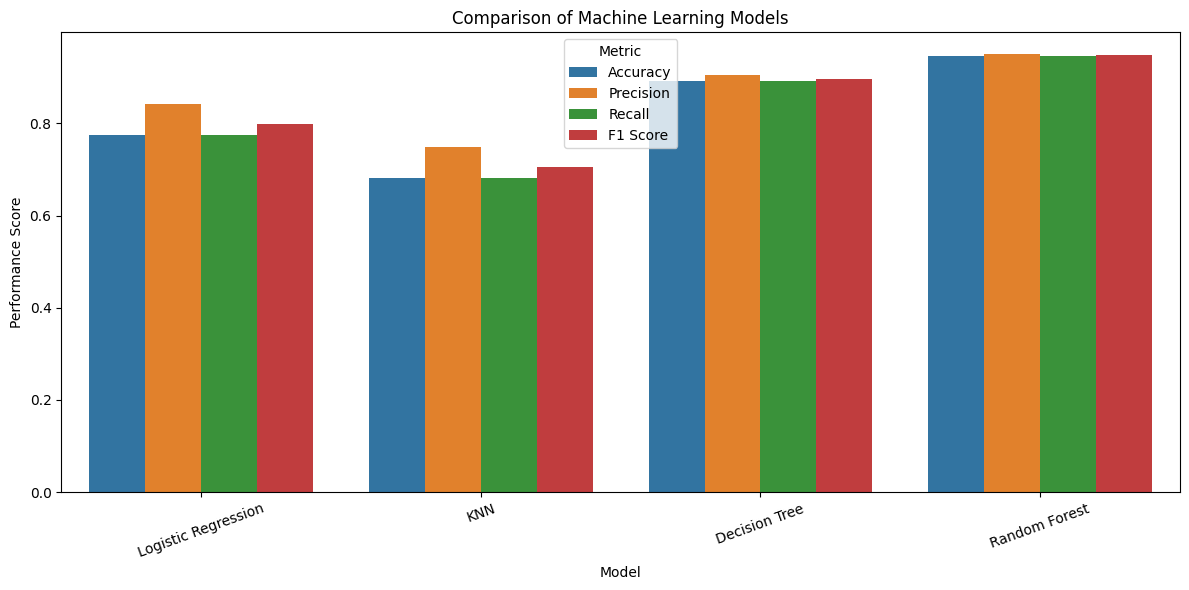

In [22]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results_df.melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    ),
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

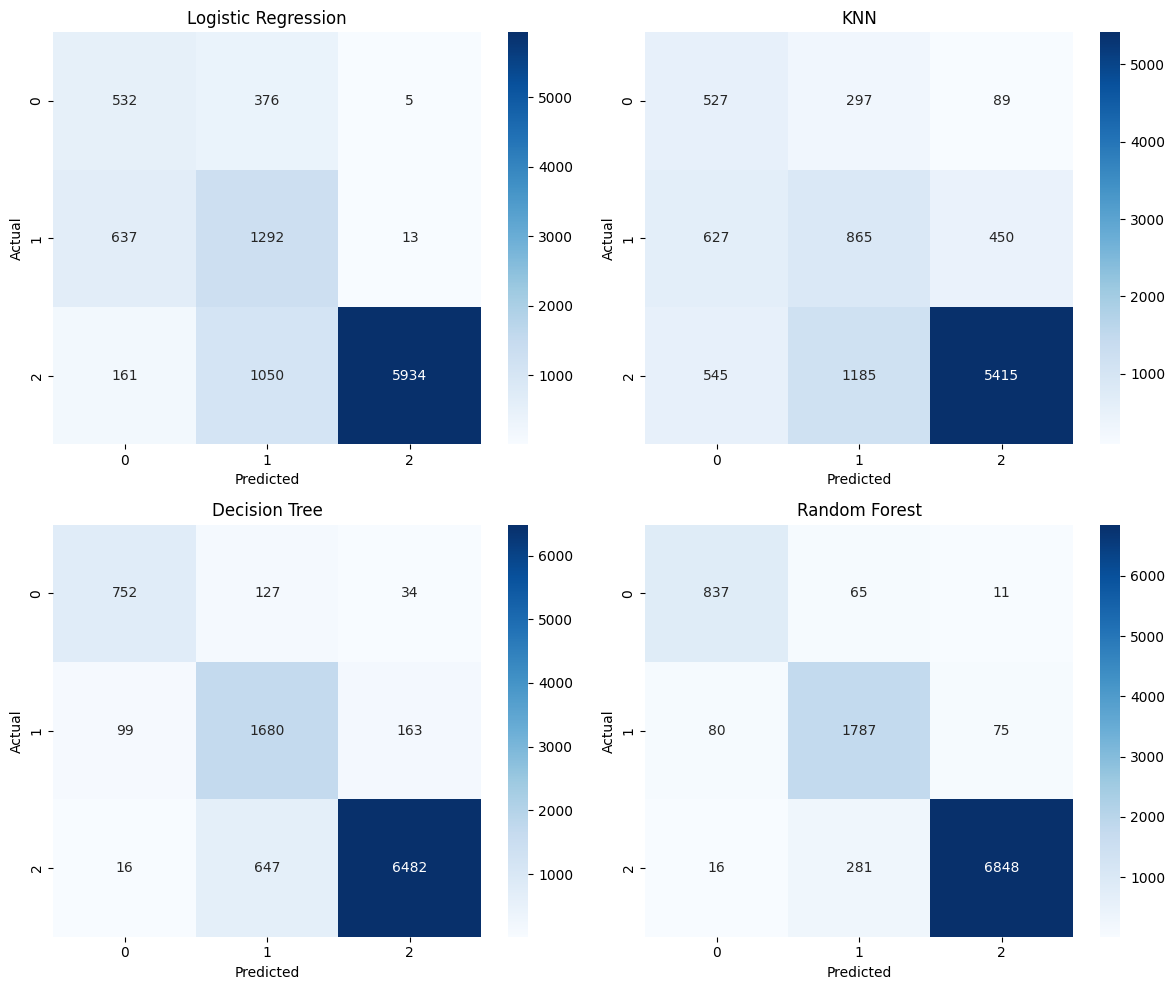

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

for ax, (name, prediction) in zip(axes.flat, models.items()):

    cm = confusion_matrix(
        y_test_sample,
        prediction,
        labels=["Low Risk", "Moderate Risk", "High Risk"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,Feature,Importance
0,Lag_1,0.160447
3,Rolling_Mean,0.145542
1,Lag_2,0.128486
6,Month,0.123664
2,Lag_3,0.120891
9,Sikkim_Melli_1,0.039250
16,Uttarakhand_Marchula_1,0.038295
15,Uttarakhand_Lambagarh,0.036929
14,Uttarakhand_Koteshwar,0.032035
12,Uttarakhand_Karnaprayag (P),0.031298


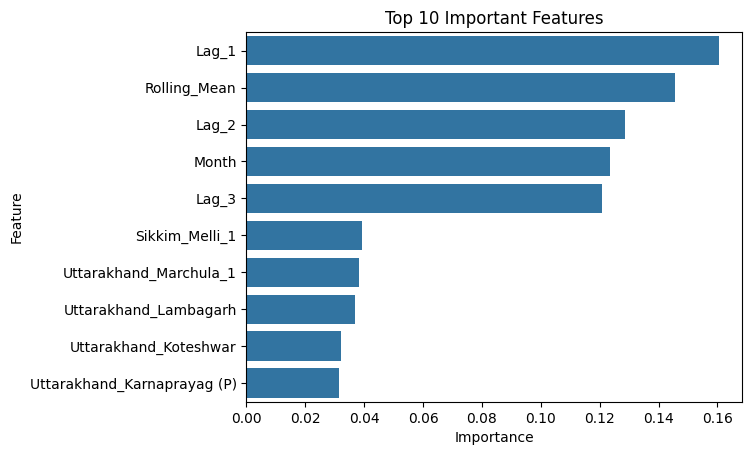

In [24]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

display(importance)

sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Important Features")
plt.show()